In [1]:
import duckdb
import matplotlib.pyplot as plt
import pandas as pd
from ga4case.path import EVENTS_FLATTENED, SESSIONS, FIGURES

In [2]:
con = duckdb.connect()
con.sql(
    f"create or replace view events as select * from read_parquet('{EVENTS_FLATTENED.as_posix()}')"
)
con.sql(
    f"create or replace view sessions as select * from read_parquet('{SESSIONS.as_posix()}')"
);

In [3]:
# Check the session table
con.sql("select * from sessions limit 2").df()

,user_pseudo_id,ga_session_id,session_number,session_start,session_end,n_events,distinct_pages,active_seconds,viewed_product,searched,began_checkout,purchased,saw_error_page,landing_page_title,landing_page_location
0,1000680.5024405394,9592114710,1,2020-12-26 09:33:49.090385,2020-12-26 09:33:53.816938,4,1,3.680,0,0,0,0,0,Google Dino Game Tee,https://shop.googlemerchandisestore.com/Google...
1,1002026.5179786689,7072627458,1,2020-12-08 23:51:32.561714,2020-12-08 23:52:06.715526,8,2,26.859,1,0,0,0,0,Home,https://shop.googlemerchandisestore.com/


In [4]:
# Check whether total sessions match the events table
con.sql("""
    select
        'events'as source,
        count(distinct(user_pseudo_id, ga_session_id)) as visits,
        count(*) as events,
        count(distinct user_pseudo_id) as users,
        count(distinct(user_pseudo_id, ga_session_id)) filter (where event_name = 'purchase') as purchase_visits
    from events
    union all
    select
        'sessions' as source,
        count(*) as visits,
        sum(n_events):: bigint as events,
        count(distinct user_pseudo_id) as users,
        sum(purchased)::bigint as purchase_visits
    from sessions  
    """).df()

,source,visits,events,users,purchase_visits
0,events,360129,4295584,270154,4848
1,sessions,360129,4295584,270154,4848


In [5]:
# Check events happen in a visit: results shown with average numbers
con.sql("""
    select
        count(*) as visits,
        round(100.0 * avg((active_seconds >= 10)::int), 1) as pct_active_10s,
        round(100.0 * avg((distinct_pages >= 2)::int), 1) as pct_two_more_pages,
        round(100.0 * avg(viewed_product), 1) as pct_viewed_product,
        round(100.0 * avg(searched), 1) as pct_searched,
        round(100.0 * avg(began_checkout), 1) as pct_began_checkout,
        round(100.0 * avg(purchased), 2) as pct_purchased,
        round(100.0 * avg(saw_error_page), 1) as pct_saw_error_page
    from sessions  
    """).df()

,visits,pct_active_10s,pct_two_more_pages,pct_viewed_product,pct_searched,pct_began_checkout,pct_purchased,pct_saw_error_page
0,360129,46.4,33.4,21.4,4.4,3.1,1.35,2.5


In [6]:
# Check top landing pages and landing page's share of all visits that view a product
con.sql("""
    select
        landing_page_title,
        count(*) as visits,
        round(100.0 * count(*) / sum(count(*)) over (), 1) as pct_visits,
        round(100.0 * avg(viewed_product), 1) as pct_viewed_product
    from sessions
    group by landing_page_title
    order by visits desc
    limit 10
    """).df()

,landing_page_title,visits,pct_visits,pct_viewed_product
0,Home,102722,28.5,25.9
1,Google Online Store,64335,17.9,11.9
2,Apparel | Google Merchandise Store,39236,10.9,9.0
3,(no page view),26446,7.3,1.3
4,YouTube | Shop by Brand | Google Merchandise S...,23444,6.5,19.3
5,Google Dino Game Tee,18449,5.1,11.9
6,Men's T-Shirts | Apparel | Google Merchandise ...,6958,1.9,35.6
7,Page Unavailable,6277,1.7,5.1
8,Drinkware | Lifestyle | Google Merchandise Store,5037,1.4,10.4
9,The Google Merchandise Store - Log In,4299,1.2,17.0


In [7]:
# Check wether measures are stable over the time

con.sql("""
    select
        date_trunc('week', session_start)::date as week,
        count(*) as visits,
        round(100.0 * avg((active_seconds >= 10)::int), 1) as pct_active_10s,
        round(avg(distinct_pages), 2) as avg_distinct_pages,
        round(100.0 * avg((distinct_pages <= 1)::int), 1) as pct_one_zero_page
    from sessions
    group by week
    order by week
    """).df()

,week,visits,pct_active_10s,avg_distinct_pages,pct_one_zero_page
0,2020-10-26,2625,50.4,2.91,67.4
1,2020-11-02,24991,51.0,3.05,61.5
2,2020-11-09,22508,53.0,3.22,59.4
3,2020-11-16,25914,53.2,3.13,59.3
4,2020-11-23,27780,50.7,3.03,62.5
5,2020-11-30,31088,51.6,3.08,61.0
6,2020-12-07,38729,46.7,2.80,66.1
7,2020-12-14,33411,45.5,2.40,67.7
8,2020-12-21,22083,43.2,2.10,71.2
9,2020-12-28,20444,40.6,1.85,74.6


Finding:
- active time keep decreasing on the week December 28th and so did distinct pages.

In [8]:
# Check what happened around the week December 28th to Jan 04th
con.sql("""
    with page_views as (
        select
            user_pseudo_id,
            ga_session_id,
            count(*) filter (where event_name = 'page_view') as n_page_views
        from events
        group by user_pseudo_id, ga_session_id
    )
    select
        session_start::date as day,
        dayname(session_start) as weekday,
        count(*) as visits,
        round(sum(n_page_views) * 1.0 / sum(distinct_pages), 2) as page_views_per_distinct_page,
        round(avg(distinct_pages), 2) as distinct_pages_per_visit,
        round(100.0 * avg((active_seconds >= 10)::int), 1) as pct_active_10s
    from sessions
    join page_views using (user_pseudo_id, ga_session_id)
    where session_start::date between '2020-12-21' and '2021-01-03'
    group by day, weekday
    order by day
""").df()

,day,weekday,visits,page_views_per_distinct_page,distinct_pages_per_visit,pct_active_10s
0,2020-12-21,Monday,4006,1.35,2.27,45.9
1,2020-12-22,Tuesday,3838,1.37,2.43,47.7
2,2020-12-23,Wednesday,3443,1.39,2.35,46.4
3,2020-12-24,Thursday,2798,1.31,2.01,41.4
4,2020-12-25,Friday,2645,1.30,1.73,36.8
5,2020-12-26,Saturday,2676,1.31,1.80,39.2
6,2020-12-27,Sunday,2677,1.32,1.77,40.8
7,2020-12-28,Monday,3356,1.47,1.99,42.4
8,2020-12-29,Tuesday,3435,1.77,1.94,41.9
9,2020-12-30,Wednesday,3213,1.79,1.84,42.1


Findings:
- Active time and distinct pages keep decreasing, lower at Christmas and New Year, but not big change on Dec 29th.
- Page views per distinct page are stable between 1.30 and 1.39 until Dec 27th. From Dec 29th to Jan 03rd, it went up about 1.8.
- Page views might be recorded differently from Dec 29, so page_view counts are not suitable for comparison across the date. But distinct pages and active time would be potentially used for the following analysis.

In [9]:
weekly_pages = con.sql("""
    with page_view as (
        select
            date_trunc('week', event_date)::date as week,
            count(*) filter (where event_name = 'page_view') *1.0
            / count(distinct (user_pseudo_id, ga_session_id)) as page_view_per_visit
        from events
        group by week
    ),
    distinct_pages as (
        select
            date_trunc('week', session_start)::date as week,
            avg(distinct_pages) as distinct_pages_per_visit
        from sessions
        group by week
    )
    select week, page_view_per_visit, distinct_pages_per_visit
    from page_view
    join distinct_pages using (week)
    where week >= '2020-11-02'
    order by week
    """).df()

weekly_pages

,week,page_view_per_visit,distinct_pages_per_visit
0,2020-11-02,4.053489,3.050538
1,2020-11-09,4.305919,3.218011
2,2020-11-16,4.218840,3.132438
3,2020-11-23,4.154491,3.027286
4,2020-11-30,4.261367,3.082797
5,2020-12-07,3.876300,2.804488
6,2020-12-14,3.380472,2.403430
7,2020-12-21,2.817733,2.095503
8,2020-12-28,3.219114,1.849442
9,2021-01-04,3.291131,1.862310


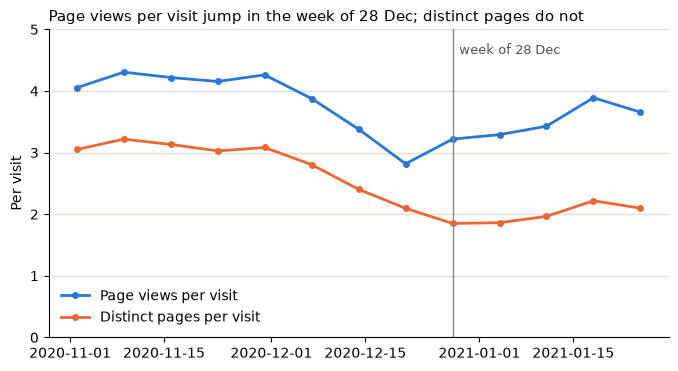

In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(
    weekly_pages["week"],
    weekly_pages["page_view_per_visit"],
    color="#2a78d6",
    linewidth=2,
    marker="o",
    markersize=4,
    label="Page views per visit",
)
ax.plot(
    weekly_pages["week"],
    weekly_pages["distinct_pages_per_visit"],
    color="#eb6834",
    linewidth=2,
    marker="o",
    markersize=4,
    label="Distinct pages per visit",
)
ax.axvline(pd.Timestamp("2020-12-28"), color="#898781", linewidth=1)
ax.text(pd.Timestamp("2020-12-29"), 4.6, "week of 28 Dec", color="#52514e", fontsize=9)
ax.set_ylim(0, 5)
ax.set_ylabel("Per visit")
ax.set_title(
    "Page views per visit jump in the week of 28 Dec; distinct pages do not",
    loc="left",
    fontsize=11,
)
ax.grid(axis="y", color="#e1e0d9", linewidth=1)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="lower left")
fig.savefig(FIGURES / "page_views_vs_distinct_pages.png", dpi=200, bbox_inches="tight")

In [11]:
# Check visits without any page view.
con.sql("""
    select
        (landing_page_title = '(no page view)') as no_page_view,
        count(*) as visits,
        round(100.0* avg((session_number = 1)::int), 1) as pct_first_visit,
        round(100.0 * avg((session_number >= 2)::int), 1) as pct_return_visit,
        median(n_events) as median_events,
        round(100.0 * avg((active_seconds >=10)::int), 1) as pct_visit_10s,
        round(100.0 * avg(viewed_product), 1) as pct_viewed_product,
        round(100.0 * avg(purchased), 2) as pct_purchased,
        round(100.0 * count(*) / sum(count(*)) over (), 1) as pct_visits
    from sessions
    group by no_page_view
    order by no_page_view   
""").df()

,no_page_view,visits,pct_first_visit,pct_return_visit,median_events,pct_visit_10s,pct_viewed_product,pct_purchased,pct_visits
0,False,333683,78.2,21.8,5.0,49.7,23.0,1.45,92.7
1,True,26446,0.8,99.2,2.0,5.1,1.3,0.00,7.3


### Summary
1. Sessions table matches events tables, including visits, events, users and purchase_visits.
2. A visit: 46.4% stays at least 10 seconds, 21.4% view a product, 3.1% started checkout and 1.35% purchased a product.
3. Landing pages: 25.9% who were Landing at Home view a product while 11.9% viewed a product for Google Online landing page group.
4. Page views thus might be recorded different from the previous period, not suitable for use. But distinct pages and active time would be potentially used for the following anlysis.
5. 7.3% of visits have no page view and no purchase activity. Because 99.2% are revisit, if we analyze return, whether we should include this no_page_view cases needs to be decided later.